In [1]:
from watts.plugin_dymond import ResultsDYMOND

In [2]:
from pathlib import Path
here = Path('.')
files = list(here.glob('*.json'))
inputs = list(here.glob('*.input'))
input_filepaths = [str(f.resolve()) for f in inputs]
filepaths = [str(f.resolve()) for f in files]


In [3]:
from watts.parameters import Parameters
from watts.results import ExecInfo, Results
obj = ResultsDYMOND(Parameters(), ExecInfo(1, 'dymond', 'name', 1), input_filepaths, filepaths)

In [4]:
# first get reactor names
import json
flows = json.load(open('recycling_scenario_flows.json'))
outputs = json.load(open('recycling_scenario_outputs.json'))
reactor_names = []
for i in outputs['input']['types']['reactor']:
    reactor_names.append(i['name'])
# reactor_names = [q for q in list(flows.keys()) if 'TOTAL' not in q]
times = outputs['times']
reactor_names

['PWR', 'ALWR', 'BWR', 'Natrium', 'ASFR']

In [5]:
csv_dict = {'years': times}

# Natural uranium

In [6]:
natlu_dict = {}
for r in reactor_names:
    natlu_dict[r] = obj.stock_fuel_natu(r, 0.00711, 0.0025)


Reactor ASFR does not take traditional fuel, most likely reprocessed fuel. So it does not use uranium. Returning zeros.


Text(0, 0.5, 'natural uranium demand [kg/year]')

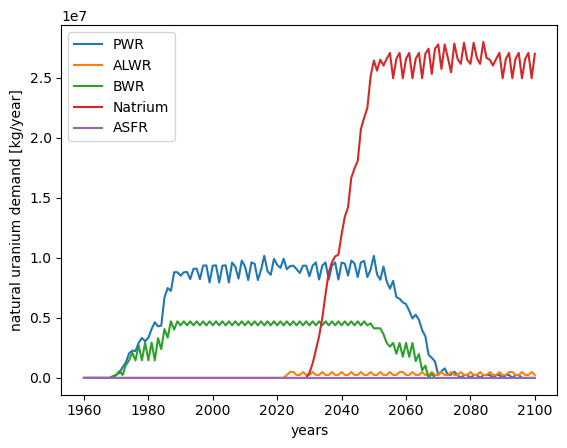

In [12]:
import matplotlib.pyplot as plt

for k,v in natlu_dict.items():
    csv_dict[f'natlu_{k}'] = v
    csv_dict[f'conversion_{k}'] = v
    plt.plot(times, v, label=k)
plt.legend()
plt.xlabel('years')
plt.ylabel('natural uranium demand [kg/year]')

# SWU

In [13]:
swu_dict = {}
for r in reactor_names:
    swu_dict[r] = obj.stock_fuel_swu_2stage(r, [0.00711, 0.1], [0.0025, 0.00711])

Reactor ASFR does not take traditional fuel, most likely reprocessed fuel. So it does not use uranium. Returning zeros.


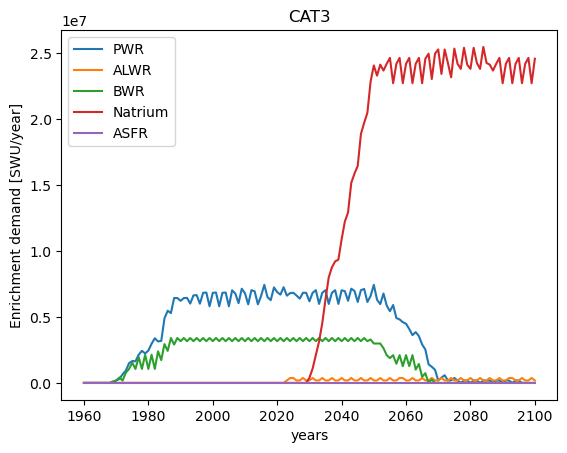

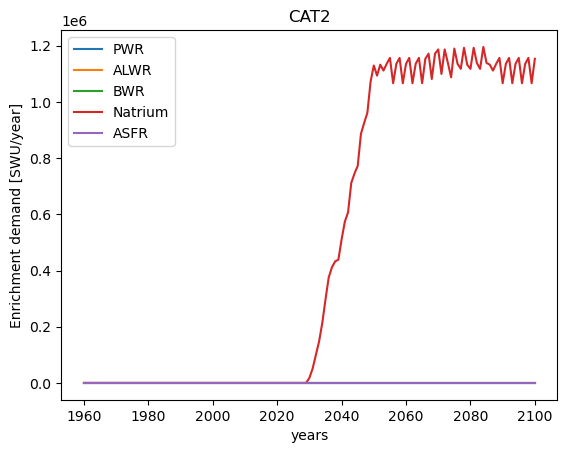

In [16]:
for indx, cat in enumerate(['CAT3', 'CAT2']):
    for k,v in swu_dict.items():
        csv_dict[f'{cat}_SWU_{k}'] = v[:,indx]
        plt.plot(times, v[:,indx], label=k)
    plt.legend()
    plt.xlabel('years')
    plt.ylabel('Enrichment demand [SWU/year]')
    plt.title(cat)
    plt.show()
    plt.close()

# Fabrication

In [17]:
fab_dict = {}
for r in reactor_names:
    fab_dict[r] = obj.fuel_fabricated(r)

Text(0, 0.5, 'Fabrication demand [kg/year]')

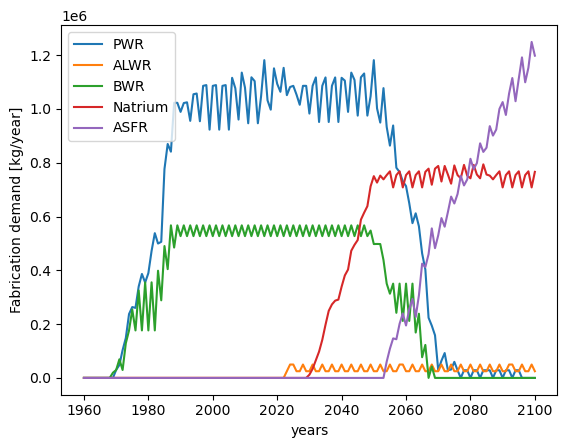

In [18]:
for k,v in fab_dict.items():
    csv_dict[f'fab_{k}'] = v
    plt.plot(times, v, label=k)
plt.legend()
plt.xlabel('years')
plt.ylabel('Fabrication demand [kg/year]')


# Reprocessing

In [21]:
# get reprocessing plant names
rep_fac_names = []
for i in outputs['input']['types']['reprocessing']:
    rep_fac_names.append(i['name'])
rep_fac_names

['reprocess_ASFR', 'reprocess_SFR']

In [ ]:
rep_dict = {}
for r in rep_fac_names:
    rep_dict[r] = obj.reprocessed_mass(r.lower()) #! why?

In [27]:
for k,v in flows['TOTAL'].items():
    print(k, len(v))

PWR 141
BWR 141
ALWR 141
Natrium 141
ASFR 141
reprocess_asfr 142
reprocess_sfr 142


Text(0, 0.5, 'UNF reprocessing [kg/year]')

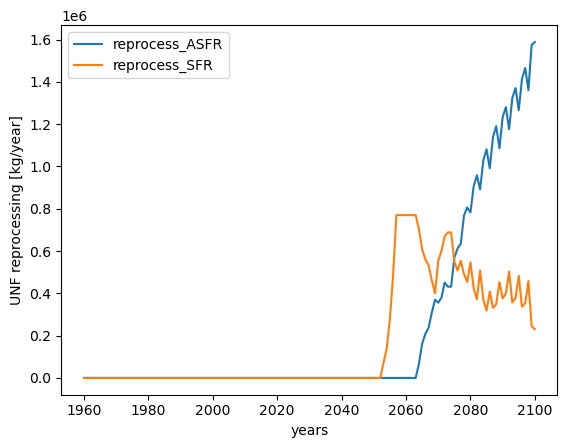

In [30]:
for k,v in rep_dict.items():
    #! check this!
    #! reprocessing arrays are one longer than the time array and other fuel arrays
    csv_dict[f'rep_{k}'] = v[:-1]
    plt.plot(times, v[:-1], label=k)
plt.legend()
plt.xlabel('years')
plt.ylabel('UNF reprocessing [kg/year]')


# Waste

In [32]:
# get wastes
#! unclear how to get HLW from reprocessing
hlw_dict = json.load(open('recycling_scenario_stocks.json'))['waste']

Text(0, 0.5, 'UNF disposed [kg/year]')

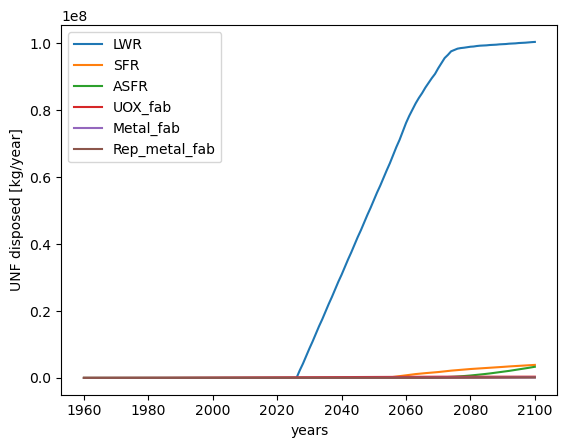

In [33]:
for k,v in hlw_dict.items():
    csv_dict[f'unf_{k}'] = v
    plt.plot(times, v, label=k)
plt.legend()
plt.xlabel('years')
plt.ylabel('UNF disposed [kg/year]')


In [41]:
import pandas as pd
df = pd.DataFrame.from_dict(csv_dict)
df = df.set_index('years')

In [44]:
df.to_csv('mass_flows.csv')